# Día 5 · Análisis e interpretación de los intervalos

**Apartado del documento que cubre este día:** 6 (Análisis e interpretación).

El documento lo dice textualmente: no quiere que se entregue sólo "IC = (7.2, 8.4)". Pide responder **ocho preguntas**. Este día responde cada una con los números del proyecto.

**Al terminar este día, cada integrante del equipo debe poder responder sin leer las ocho preguntas del apartado 6.**

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

RAIZ = Path.cwd().parent if Path.cwd().name == "clases" else Path.cwd()
poblacion = pd.read_csv(RAIZ / "data" / "processed" / "poblacion_clientes.csv")
muestra = pd.read_csv(RAIZ / "data" / "processed" / "muestra_clientes_n1000.csv")
N = len(poblacion)
n = len(muestra)
print("Clientes en la población (N):", N)
print("Clientes en la muestra (n):", n)

Clientes en la población (N): 10000
Clientes en la muestra (n): 1000


---
## Paso 1 · Las ocho preguntas del documento

| # | Pregunta del documento | Dónde se responde |
|---|---|---|
| 1 | ¿Qué significa el intervalo? | Paso 2 |
| 2 | ¿Qué parámetro se está estimando? | Paso 2 |
| 3 | ¿Qué nivel de confianza utilizaron? | Paso 3 |
| 4 | ¿Por qué seleccionaron ese nivel? | Paso 3 |
| 5 | ¿Qué sucede si aumentara el tamaño de muestra? | Paso 5 |
| 6 | ¿Qué sucedería si utilizaran 99 % de confianza? | Paso 4 |
| 7 | ¿El intervalo sería más amplio o más estrecho? | Paso 4 |
| 8 | ¿Qué limitaciones tiene su estimación? | Paso 8 |

Además, los pasos 6 y 7 usan la población completa para **comprobar** que el método funciona.

Primero se calculan los valores que se usarán en todo el día:

In [2]:
fcpf = np.sqrt((N - n) / (N - 1))
p_gorro = muestra["abandono"].mean()
error_estandar_p = np.sqrt(p_gorro * (1 - p_gorro) / n) * fcpf
print("Proporción de abandono en la muestra:", p_gorro)
print("Error estándar corregido de la proporción:", round(error_estandar_p, 4))

Proporción de abandono en la muestra: 0.206
Error estándar corregido de la proporción: 0.0121


---
## Paso 2 · Preguntas 1 y 2: qué significa cada intervalo y qué parámetro estima

| Pregunta | Parámetro que se estima | Intervalo al 95 % | Qué significa |
|---|---|---|---|
| P1 | $p$: proporción de los 10,000 clientes que abandonan | (0.182, 0.230) | Entre 18.2 % y 23.0 % de los clientes del banco abandonan |
| P2 | $\mu$: saldo promedio de todos los clientes que abandonan | (83,665 €, 99,458 €) | Cada cliente que se va se lleva en promedio entre 83,665 € y 99,458 € |
| P3 | $p_1 - p_2$: proporción de abandono de inactivos menos la de activos | (0.063, 0.159) | Los inactivos abandonan entre 6.3 y 15.9 puntos porcentuales más. No contiene el 0 |
| P4 | $\mu_1 - \mu_2$: edad promedio de quienes se van menos la de quienes se quedan | (8.0, 10.8) años | Quienes se van son entre 8.0 y 10.8 años mayores en promedio. No contiene el 0 |

**Lo que significa un intervalo de confianza en general:** es un rango de valores, calculado con la muestra, construido con un método que contiene al parámetro de la población en el 95 % de las muestras posibles.

**Cuidado:** los parámetros son de **la población** (los 10,000 clientes), no de la muestra. De la muestra ya conocemos todo; el intervalo sirve para hablar de la población.

---
## Paso 3 · Preguntas 3 y 4: qué nivel de confianza y por qué

**Nivel utilizado:** 95 % en los cuatro intervalos.

**Por qué 95 %:**
1. Es el nivel estándar en investigación y en empresas, por lo que los resultados se pueden comparar con otros estudios.
2. Equilibra dos cosas que se contraponen: la **seguridad** de que el intervalo contenga el parámetro y la **precisión** (que el intervalo sea angosto).
3. Las consecuencias de equivocarse en este estudio son económicas y se pueden corregir (una campaña se puede ajustar o detener). No justifican el 99 %, que se usa cuando un error es muy grave (por ejemplo, en medicina).
4. La decisión involucra dinero, así que el 90 % sería poco exigente.

---
## Paso 4 · Preguntas 6 y 7: qué pasaría con 99 % de confianza

Al cambiar el nivel de confianza sólo cambia el **valor crítico** $z$. Se calcula para 90 %, 95 % y 99 %:

In [3]:
z_90 = stats.norm.ppf(1 - 0.10 / 2)
z_95 = stats.norm.ppf(1 - 0.05 / 2)
z_99 = stats.norm.ppf(1 - 0.01 / 2)
print("Valor crítico z para 90 %:", round(z_90, 3))
print("Valor crítico z para 95 %:", round(z_95, 3))
print("Valor crítico z para 99 %:", round(z_99, 3))

Valor crítico z para 90 %: 1.645
Valor crítico z para 95 %: 1.96
Valor crítico z para 99 %: 2.576


In [4]:
intervalo_90 = (p_gorro - z_90 * error_estandar_p, p_gorro + z_90 * error_estandar_p)
intervalo_95 = (p_gorro - z_95 * error_estandar_p, p_gorro + z_95 * error_estandar_p)
intervalo_99 = (p_gorro - z_99 * error_estandar_p, p_gorro + z_99 * error_estandar_p)
ancho_90 = intervalo_90[1] - intervalo_90[0]
ancho_95 = intervalo_95[1] - intervalo_95[0]
ancho_99 = intervalo_99[1] - intervalo_99[0]
print("Intervalo al 90 %:", (float(round(intervalo_90[0], 4)), float(round(intervalo_90[1], 4))), "| ancho:", round(ancho_90, 4))
print("Intervalo al 95 %:", (float(round(intervalo_95[0], 4)), float(round(intervalo_95[1], 4))), "| ancho:", round(ancho_95, 4))
print("Intervalo al 99 %:", (float(round(intervalo_99[0], 4)), float(round(intervalo_99[1], 4))), "| ancho:", round(ancho_99, 4))
print("El intervalo al 99 % es", round(ancho_99 / ancho_95, 2), "veces el ancho del de 95 %")
print("El intervalo al 90 % es", round(ancho_90 / ancho_95, 2), "veces el ancho del de 95 %")

Intervalo al 90 %: (0.186, 0.226) | ancho: 0.0399
Intervalo al 95 %: (0.1822, 0.2298) | ancho: 0.0476
Intervalo al 99 %: (0.1747, 0.2373) | ancho: 0.0625
El intervalo al 99 % es 1.31 veces el ancho del de 95 %
El intervalo al 90 % es 0.84 veces el ancho del de 95 %


**Respuesta a las preguntas 6 y 7:** con 99 % de confianza el intervalo sería **más amplio**: pasaría de (0.182, 0.230) a (0.175, 0.237), un **31 % más ancho**. Con 90 % sería un 16 % más estrecho.

**Por qué:** para acertar más veces, el intervalo tiene que cubrir más valores. Es un intercambio: con los mismos datos, **más confianza significa menos precisión**. La única forma de tener las dos es aumentar el tamaño de la muestra (Paso 5).

Lo mismo pasa en los cuatro intervalos del proyecto: todos son 31 % más anchos al 99 %.

---
## Paso 5 · Pregunta 5: qué pasa si aumenta el tamaño de la muestra

El margen de error de una proporción es:

$$\text{margen} = z \cdot \sqrt{\frac{\hat p(1-\hat p)}{n}} \cdot \sqrt{\frac{N-n}{N-1}}$$

$n$ está dividiendo dentro de una raíz cuadrada. Se calcula el margen para varios tamaños de muestra:

In [5]:
tamanos = np.array([250, 500, 1000, 2000, 4000, 10000])
errores_estandar = np.sqrt(p_gorro * (1 - p_gorro) / tamanos)
factores_correccion = np.sqrt((N - tamanos) / (N - 1))
margenes = z_95 * errores_estandar * factores_correccion
tabla_margenes = pd.DataFrame({"Tamaño de muestra": tamanos, "Margen de error (puntos %)": (margenes * 100).round(2)})
print(tabla_margenes.to_string(index=False))

 Tamaño de muestra  Margen de error (puntos %)
               250                        4.95
               500                        3.46
              1000                        2.38
              2000                        1.59
              4000                        0.97
             10000                        0.00


**Respuesta a la pregunta 5:** si aumenta el tamaño de la muestra, el intervalo se vuelve **más estrecho** (más preciso). El nivel de confianza no cambia.

**Tres observaciones de la tabla:**
1. Con 1,000 clientes el margen fue de **±2.38 puntos**, mejor que los ±3 planeados. La razón: el tamaño se calculó con $p$ = 0.5 y la proporción real (0.206) tiene menos variación.
2. Pasar de 1,000 a 4,000 clientes (4 veces más trabajo) sólo baja el margen de 2.38 a 0.97 puntos. Sin la corrección por población, cuadruplicar la muestra reduce el margen exactamente a la mitad.
3. Con $n$ = 10,000 (toda la población), el margen es 0: ya no hay nada que estimar.

---
## Paso 6 · Comprobación: qué significa realmente el 95 %

En la vida real sólo hay una muestra y no se puede comprobar si el intervalo acertó. En nuestro proyecto tenemos a los 10,000 clientes, así que podemos hacer el experimento:
1. Sacar **1,000 muestras diferentes** de 1,000 clientes cada una.
2. Calcular con cada muestra su intervalo al 95 %.
3. Contar cuántos intervalos contienen la proporción real de la población.

Si el método funciona, cerca de 950 de 1,000 intervalos deben contenerla.

In [6]:
p_real = poblacion["abandono"].mean()
valores_poblacion = poblacion["abandono"].to_numpy(dtype=np.int8)
generador = np.random.default_rng(123)
poblacion_repetida = np.tile(valores_poblacion, (1000, 1))
poblaciones_revueltas = generador.permuted(poblacion_repetida, axis=1)
muestras_simuladas = poblaciones_revueltas[:, :n]
proporciones_simuladas = muestras_simuladas.mean(axis=1)
errores_simulados = np.sqrt(proporciones_simuladas * (1 - proporciones_simuladas) / n) * fcpf
limites_inferiores = proporciones_simuladas - z_95 * errores_simulados
limites_superiores = proporciones_simuladas + z_95 * errores_simulados
contiene_p_real = (limites_inferiores <= p_real) & (p_real <= limites_superiores)
print("Proporción real en la población:", p_real)
print("Número de muestras simuladas:", len(proporciones_simuladas))
print("Intervalos que contienen la proporción real:", contiene_p_real.sum())
print("Porcentaje de aciertos:", round(contiene_p_real.mean() * 100, 1))

Proporción real en la población: 0.2037
Número de muestras simuladas: 1000
Intervalos que contienen la proporción real: 946
Porcentaje de aciertos: 94.6


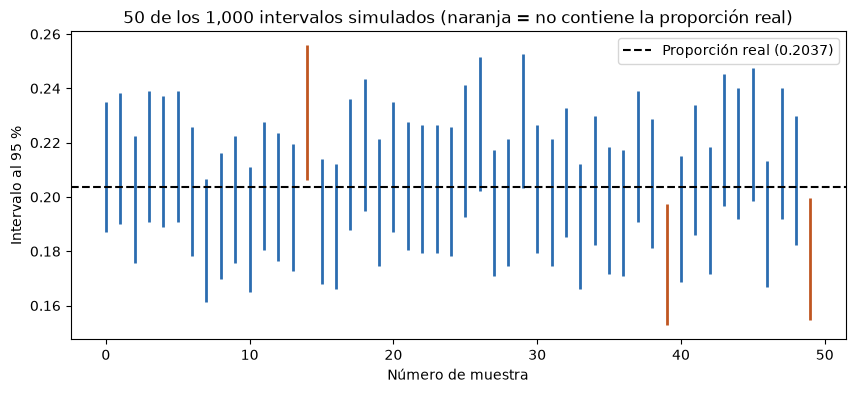

In [7]:
primeros = np.arange(50)
colores = np.where(contiene_p_real[:50], "#2b6cb0", "#c05621")
figura, eje = plt.subplots(figsize=(10, 4))
eje.vlines(primeros, limites_inferiores[:50], limites_superiores[:50], colors=colores, linewidth=2)
eje.axhline(p_real, color="black", linestyle="--", label="Proporción real (0.2037)")
eje.set_xlabel("Número de muestra")
eje.set_ylabel("Intervalo al 95 %")
eje.set_title("50 de los 1,000 intervalos simulados (naranja = no contiene la proporción real)")
eje.legend()
plt.show()

**Lectura:** cerca del 95 % de los intervalos contienen la proporción real y cerca del 5 % no (en naranja). Esto es lo que significa "95 % de confianza": la **tasa de acierto del método**. Con una sola muestra no se sabe si nuestro intervalo es de los que aciertan o de los que fallan.

---
## Paso 7 · Comprobación: ¿nuestros cuatro intervalos acertaron?

Se compara cada intervalo del proyecto con el valor real de la población:

In [8]:
saldo_real = poblacion.loc[poblacion["abandono"] == 1, "saldo"].mean()
p_real_inactivos = poblacion.loc[poblacion["miembro_activo"] == 0, "abandono"].mean()
p_real_activos = poblacion.loc[poblacion["miembro_activo"] == 1, "abandono"].mean()
diferencia_p_real = p_real_inactivos - p_real_activos
edad_real_se_va = poblacion.loc[poblacion["abandono"] == 1, "edad"].mean()
edad_real_se_queda = poblacion.loc[poblacion["abandono"] == 0, "edad"].mean()
diferencia_edad_real = edad_real_se_va - edad_real_se_queda
print("P1 · valor real:", round(p_real, 4), "| intervalo: (0.1822, 0.2298) | ¿lo contiene?:", 0.1822 <= p_real <= 0.2298)
print("P2 · valor real:", round(saldo_real, 2), "| intervalo: (83664.74, 99458.33) | ¿lo contiene?:", 83664.74 <= saldo_real <= 99458.33)
print("P3 · valor real:", round(diferencia_p_real, 4), "| intervalo: (0.0632, 0.1590) | ¿lo contiene?:", 0.0632 <= diferencia_p_real <= 0.1590)
print("P4 · valor real:", round(diferencia_edad_real, 2), "| intervalo: (8.04, 10.78) | ¿lo contiene?:", 8.04 <= diferencia_edad_real <= 10.78)

P1 · valor real: 0.2037 | intervalo: (0.1822, 0.2298) | ¿lo contiene?: True
P2 · valor real: 91108.54 | intervalo: (83664.74, 99458.33) | ¿lo contiene?: True
P3 · valor real: 0.1258 | intervalo: (0.0632, 0.1590) | ¿lo contiene?: True
P4 · valor real: 7.43 | intervalo: (8.04, 10.78) | ¿lo contiene?: False


**Resultado:** tres de los cuatro intervalos contienen el valor real. El de P4 **no lo contiene**: la diferencia real de edades es 7.43 años y el intervalo fue de 8.04 a 10.78.

**Cómo se explica esto en la exposición (es un punto a favor, no en contra):**
1. Con 95 % de confianza, se espera que aproximadamente 1 de cada 20 intervalos falle. Que falle uno de cuatro es posible por azar.
2. Por eso se habla de **confianza** y no de **certeza**.
3. La conclusión de P4 no cambia: el intervalo no contenía el 0 y la diferencia real (7.43 años) tampoco es 0. Quienes abandonan sí son mayores.
4. Cada intervalo tiene 95 % de confianza por separado. La probabilidad de que los **cuatro** acierten a la vez es menor.

---
## Paso 8 · Pregunta 8: limitaciones de la estimación

| Limitación | Qué significa |
|---|---|
| Origen del dataset | No se sabe qué banco es ni de qué fechas son los datos. Las conclusiones aplican a estos 10,000 clientes, no a toda la banca europea |
| Sólo error de muestreo | El intervalo considera el error por tomar una muestra. No considera errores de captura en los datos (por ejemplo, un abandono mal registrado) |
| Estudio observacional | P3 y P4 muestran diferencias entre grupos, no causas. No se puede decir que la inactividad o la edad provoquen el abandono |
| Aproximación normal | Las fórmulas usan la distribución normal o la t. Funcionan con muestras grandes como la nuestra; se comprobó con bootstrap y con simulación |
| Varios intervalos a la vez | Cada intervalo tiene 95 % de confianza por separado. La confianza de que los cuatro acierten juntos es menor (al menos 80 %), y de hecho uno falló |

---
## Preguntas que puede hacer el profesor (apartado 6)

**1. ¿Qué significa su intervalo de P1?**
Que, con 95 % de confianza, la proporción de clientes del banco que abandonan está entre 18.2 % y 23.0 %.

**2. ¿Qué parámetro estima?**
La proporción de abandono de los 10,000 clientes, $p$. No la de la muestra.

**3. ¿Qué nivel de confianza usaron y por qué?**
95 %. Es el estándar, equilibra seguridad y precisión, y las consecuencias de un error son económicas y corregibles.

**4. ¿Qué pasa si usan 99 %?**
El intervalo se vuelve 31 % más amplio: de (0.182, 0.230) a (0.175, 0.237).

**5. ¿Qué pasa si aumentan la muestra?**
El intervalo se vuelve más estrecho. Con 4,000 clientes el margen bajaría de 2.38 a 0.97 puntos porcentuales.

**6. ¿Por qué su margen fue menor a los 3 puntos planeados?**
Porque el tamaño se calculó con $p$ = 0.5, el caso de mayor variación, y la proporción observada fue 0.206.

**7. ¿Cómo saben que el método funciona?**
Simulamos 1,000 muestras y cerca del 95 % de sus intervalos contuvieron la proporción real.

**8. Uno de sus intervalos falló. ¿Eso invalida su trabajo?**
No. Con 95 % de confianza se espera que fallen cerca de 5 de cada 100 intervalos. Además, la conclusión de P4 se mantiene: la diferencia real de edades (7.43 años) es positiva.

**9. ¿Cuáles son las limitaciones?**
Banco y fechas desconocidos, sólo se considera el error de muestreo, el estudio no prueba causas y los cuatro intervalos juntos tienen menos de 95 % de confianza.

---
## Tarea del Día 5 (para todo el equipo)

Repartan las ocho preguntas del documento. Cada integrante responde en voz alta, sin leer, las que le tocaron. Practiquen especialmente la pregunta 8 del profesor: es la más probable si él revisa la validación.

➡️ **Día 6:** Apartado 7 (Teoría de decisión) y Decisiones metodológicas.